In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import json

from quantify_core.data.handling import (
    default_datadir,
    get_latest_tuid,
    get_tuids_containing,
    load_dataset,
    locate_experiment_container,
    set_datadir,
)

In [2]:
set_datadir(default_datadir())

Data will be saved in:
/home/pschaefers/quantify-data


In [3]:
qubits = ['D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'X3', 'X4', 'Z1', 'Z2', 'Z3', 'Z4']

In [5]:
tuids = get_tuids_containing(f"SSRO QND {qubits[0]}", t_start='20250927-005237')
folders = [locate_experiment_container(tuid) for tuid in tuids]

def find_and_collect(root_dirs, qubit):
    assignfid_av = []
    assignfid_01 = []
    qndpifid = []

    assignfid_av_fstate = []
    assignfid_01_fstate = []
    assignfid_02_fstate = []
    assignfid_12_fstate = []
    qndpifid_fstate = []
    
    for root_dir in root_dirs:
        for dirpath, _, filenames in os.walk(root_dir):
            if "quantities_of_interest.json" in filenames:
                file_path = os.path.join(dirpath, "quantities_of_interest.json")
                with open(file_path, "r") as f:
                    data = json.load(f)
        
                if "F_assignment_raw_12_D2" in data:
                    # Append to main lists
                    assignfid_av_fstate.append(data[f"F_assignment_raw_{qubit}"])
                    assignfid_01_fstate.append(data[f"F_assignment_raw_01_{qubit}"])
                    assignfid_02_fstate.append(data[f"F_assignment_raw_02_{qubit}"])
                    assignfid_12_fstate.append(data[f"F_assignment_raw_12_{qubit}"])
                    qndpifid_fstate.append(data[f"F_QND_pi_{qubit}"])
    
                    
                else:
                    # Append to main lists
                    assignfid_av.append(data[f"F_assignment_raw_{qubit}"])
                    assignfid_01.append(data[f"F_assignment_raw_01_{qubit}"])
                    qndpifid.append(data[f"F_QND_pi_{qubit}"])
                    
    return assignfid_av, assignfid_01, qndpifid ,assignfid_av_fstate, assignfid_01_fstate, assignfid_02_fstate, assignfid_12_fstate, qndpifid_fstate

In [6]:
def get_fids(qubits):
    results = {}

    for qubit in qubits:
        results[qubit] = {
            "assignfid_av": [],
            "assignfid_01": [],
            "qndpifid": [],
            "assignfid_av_fstate": [],
            "assignfid_01_fstate": [],
            "assignfid_02_fstate": [],
            "assignfid_12_fstate": [],
            "qndpifid_fstate": []
        }

        tuids = get_tuids_containing(f"SSRO QND {qubit}",  t_start='20250927000000', t_stop='20250929000000')
        folders = [locate_experiment_container(tuid) for tuid in tuids]
        folders = [str(f) for f in folders if f is not None]
        folders = sorted(folders) 

        for root_dir in folders:
            for dirpath, _, filenames in os.walk(root_dir):
                if "quantities_of_interest.json" in filenames:
                    file_path = os.path.join(dirpath, "quantities_of_interest.json")
                    
                    with open(file_path, "r") as f:
                        data = json.load(f)

                    if f"F_assignment_raw_12_{qubit}" in data:
                        results[qubit]["assignfid_av_fstate"].append(data[f"F_assignment_raw_{qubit}"])
                        results[qubit]["assignfid_01_fstate"].append(data[f"F_assignment_raw_01_{qubit}"])
                        results[qubit]["assignfid_02_fstate"].append(data[f"F_assignment_raw_02_{qubit}"])
                        results[qubit]["assignfid_12_fstate"].append(data[f"F_assignment_raw_12_{qubit}"])
                        results[qubit]["qndpifid_fstate"].append(data[f"F_QND_pi_{qubit}"])
                    else:
                        results[qubit]["assignfid_av"].append(data[f"F_assignment_raw_{qubit}"])
                        results[qubit]["assignfid_01"].append(data[f"F_assignment_raw_01_{qubit}"])
                        results[qubit]["qndpifid"].append(data[f"F_QND_pi_{qubit}"])

    os.makedirs("data_gitlab", exist_ok=True)  # Creates directory if it doesn't exist
    with open("data_gitlab/fidelities.json", "w", encoding="utf-8") as f:
        json.dump(results, f, ensure_ascii=False, indent=4)
        
    return results


In [7]:
def get_T1(qubits):
    # Initialize dict for this qubit
    results = {qubit: [] for qubit in qubits} 
    
    for qubit in qubits:
        tuids = get_tuids_containing(f"T1 experiment {qubit}", t_start='20250927000000', t_stop='20250929000000')
        folders = [locate_experiment_container(tuid) for tuid in tuids]
        folders = [str(f) for f in folders if f is not None]
        folders = sorted(folders)        
        
        for root_dir in folders:
            for dirpath, _, filenames in os.walk(root_dir):
                if "quantities_of_interest.json" in filenames:
                    file_path = os.path.join(dirpath, "quantities_of_interest.json")

                    if "T1Analysis" in file_path:
                        with open(file_path, "r") as f:
                            data = json.load(f)
    
                        T1 = data.get("T1")   # safe access
                        if isinstance(T1, dict) and "nominal_value" in T1:
                            results[qubit].append(T1["nominal_value"])

    os.makedirs("data_gitlab", exist_ok=True)  # Creates directory if it doesn't exist
    with open("data_gitlab/T1s.json", "w", encoding="utf-8") as f:
        json.dump(results, f, ensure_ascii=False, indent=4)
        
    return results

In [8]:
T1s = get_T1(qubits)
fids = get_fids(qubits)

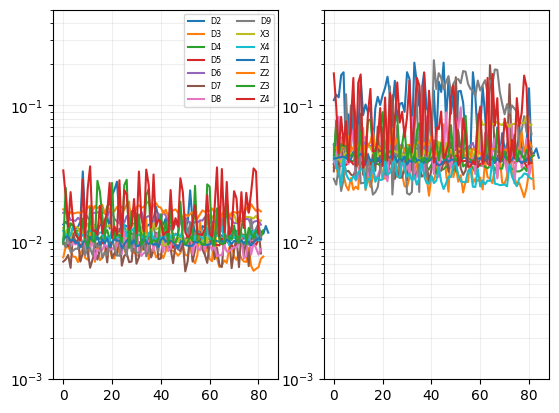

In [15]:
fig, axes = plt.subplots(ncols=2)
ax0 = axes[0]
ax1 = axes[1]

for qubit in qubits:
# for qubit in ["D9", "D2", "Z4"]:
    ax0.plot(1-np.array(fids[qubit]['assignfid_01']), label=qubit)
    ax1.plot(1-np.array(fids[qubit]['qndpifid']), label=qubit)

ax0.legend(fontsize='xx-small',ncols=2)
ax0.grid(which='both', alpha=.2)
ax1.grid(which='both', alpha =.2)

ax0.set_ylim(1e-3,0.5)
ax1.set_ylim(1e-3,0.5)

ax0.set_yscale('log')
ax1.set_yscale('log')

plt.show()

In [ ]:
means = 

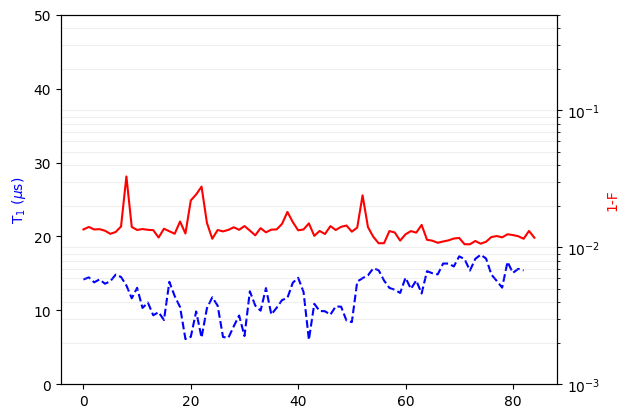

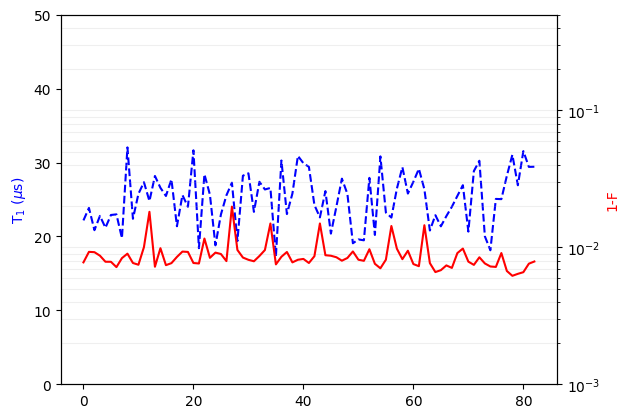

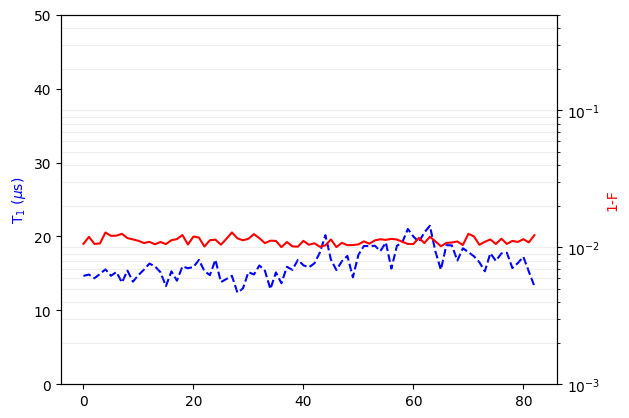

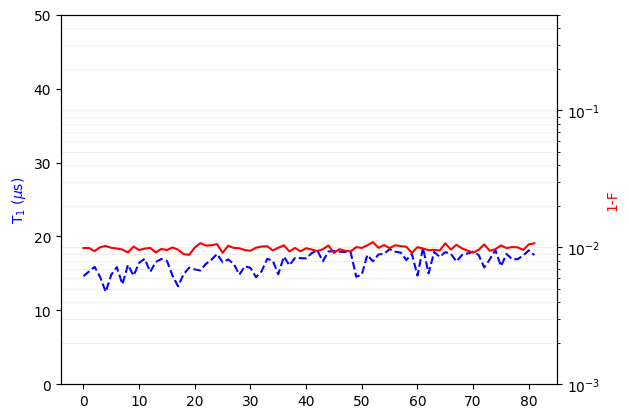

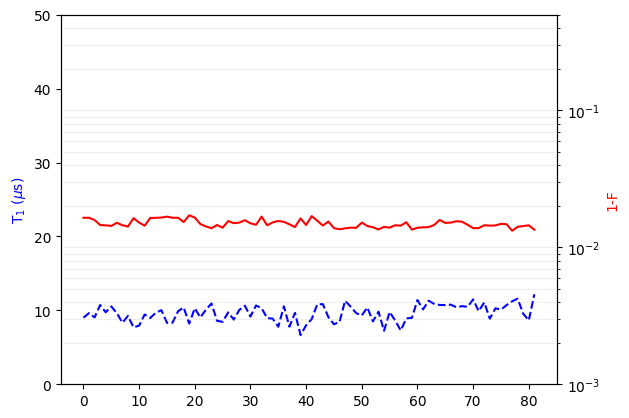

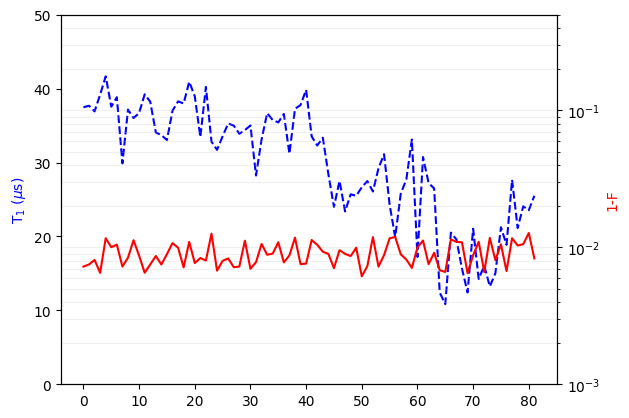

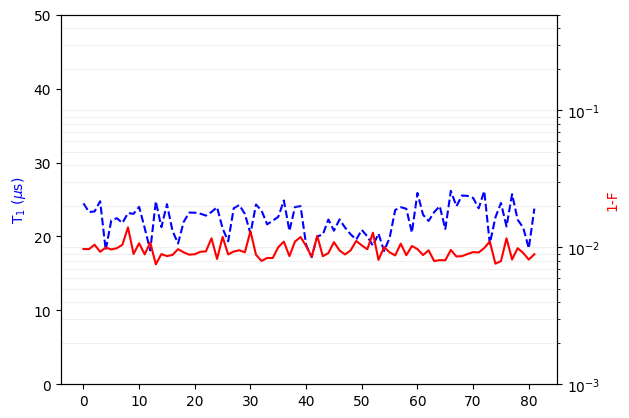

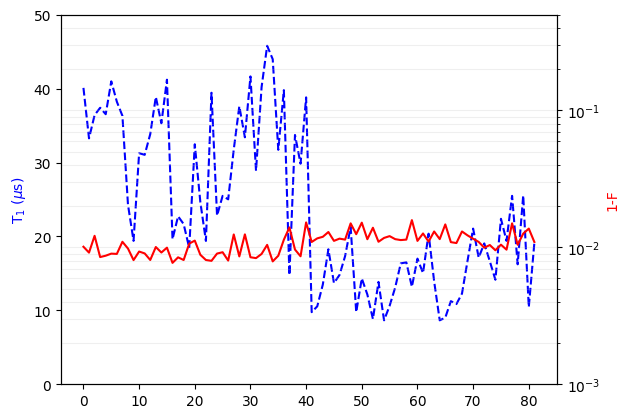

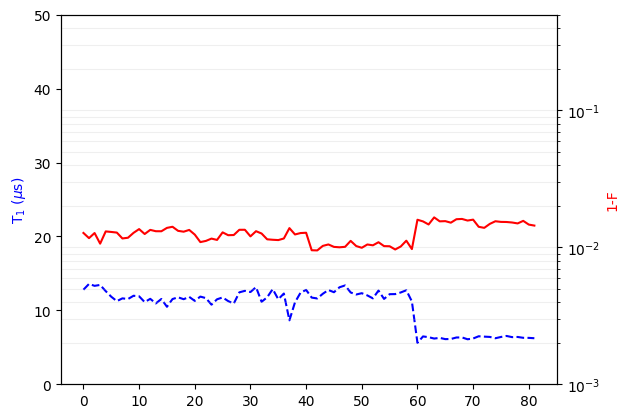

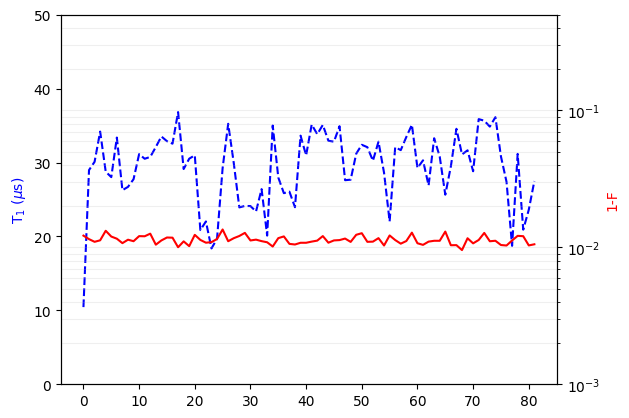

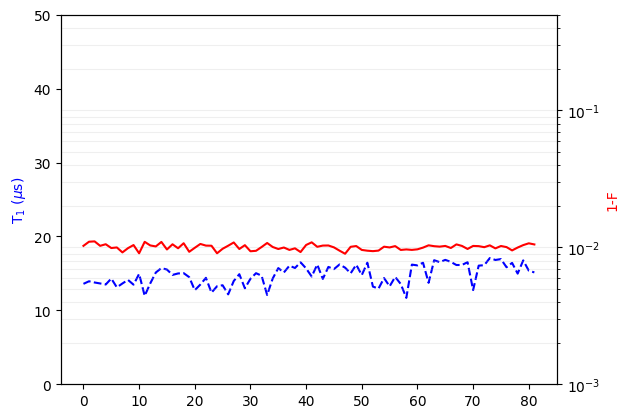

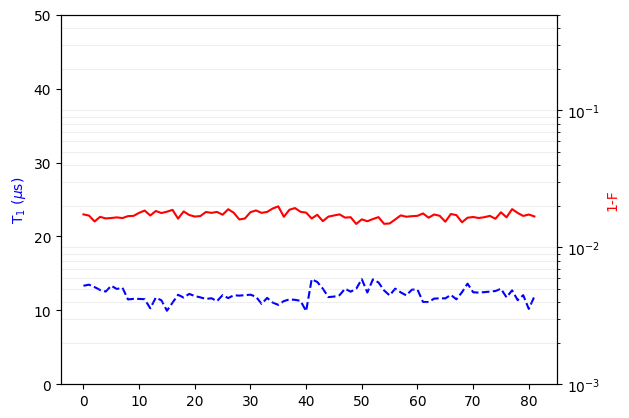

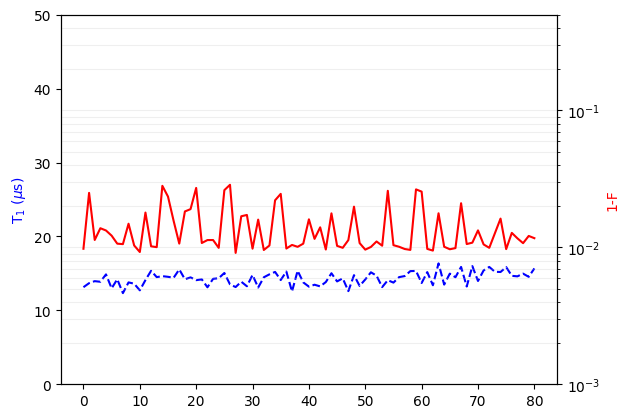

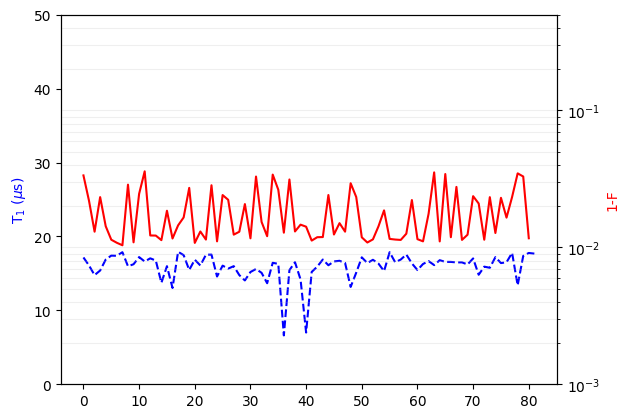

In [208]:
for qubit in qubits:
    fig, ax1 = plt.subplots()
    
    ax2 = ax1.twinx()
    
    ax1.plot(np.array(T1s[qubit])*1e6, color='blue',ls='--')
    ax1.set_ylabel('T1', color='blue')
    ax1.set_ylim(0,50)
    ax1.set_ylabel(r'T$_1$ ($\mu$s)', color='blue')

    
    ax2.plot(1-np.array(fids[qubit]['assignfid_av']),color='red')
    ax2.set_yscale('log')
    ax2.set_ylim(1e-3,0.5)
    ax2.set_ylabel('1-F', color='red')

    ax2.grid(which='both', alpha=0.2)
    
    plt.show()

In [214]:
for qubit in qubits:
    print(f"T1 var: {np.std(np.array(T1s[qubit]))*1e6} Fidelity var: {np.std(np.array(fids[qubit]['assignfid_av']))}")

T1 var: 3.003195671041785 Fidelity var: 0.0035173123435134988
T1 var: 3.6889221436922264 Fidelity var: 0.0023238828792897363
T1 var: 1.9563342118148617 Fidelity var: 0.0006796444081409017
T1 var: 1.3079859199648405 Fidelity var: 0.0004414507293938806
T1 var: 1.151493738168789 Fidelity var: 0.0009608988844862174
T1 var: 7.952376657436507 Fidelity var: 0.001769234639182893
T1 var: 2.1434006272011032 Fidelity var: 0.0012739046295416564
T1 var: 10.671968842353666 Fidelity var: 0.001996335385009324
T1 var: 2.6116132073789524 Fidelity var: 0.001946639991467736
T1 var: 4.924541368856966 Fidelity var: 0.0007869998200141316
T1 var: 1.375230623722415 Fidelity var: 0.0004765790577051552
T1 var: 0.912335792236125 Fidelity var: 0.0010654544862932901
T1 var: 0.8939434458306796 Fidelity var: 0.005492961098001022
T1 var: 1.8282672417285062 Fidelity var: 0.007766959521849269


In [167]:
qubit='D2'
print(len(T1s[qubit]))
print(len(fids[qubit]['qndpifid']))

83
85


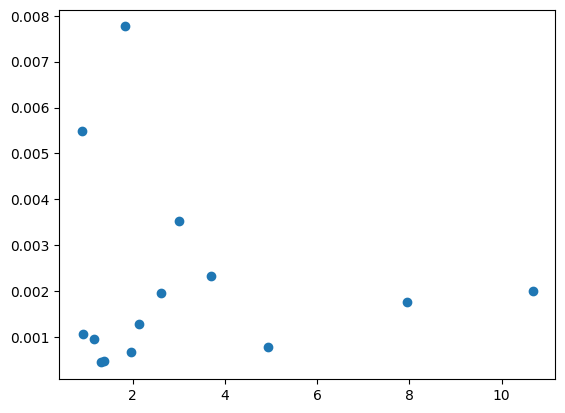

In [219]:
T1_std = []
fid_std = []

for qubit in qubits:
    T1_std.append(np.std(np.array(T1s[qubit]))*1e6)
    fid_std.append(np.std(np.array(fids[qubit]['assignfid_av'])))

plt.plot(T1_std,fid_std,"o")
plt.show()

In [ ]:
# def get_fidelities(qubits, t_start, t_stop):
#     results = {}

#     for qubit in qubits:
        results[qubit] = {
            "assignfid_av": [],
            "assignfid_01": [],
            "qndpifid": [],
            "assignfid_av_fstate": [],
            "assignfid_01_fstate": [],
            "assignfid_02_fstate": [],
            "assignfid_12_fstate": [],
            "qndpifid_fstate": []
        }

#         tuids = get_tuids_containing(f"SSRO QND {qubit}",  t_start=t_start, t_stop=t_stop)
#         folders = [locate_experiment_container(tuid) for tuid in tuids]
#         folders = [str(f) for f in folders if f is not None]
#         folders = sorted(folders) 

#         for root_dir in folders:
#             for dirpath, _, filenames in os.walk(root_dir):
#                 if "quantities_of_interest.json" in filenames:
#                     file_path = os.path.join(dirpath, "quantities_of_interest.json")
                    
#                     with open(file_path, "r") as f:
#                         data = json.load(f)

#                     if f"F_assignment_raw_12_{qubit}" in data:
#                         results[qubit]["assignfid_av_fstate"].append(data[f"F_assignment_raw_{qubit}"])
#                         results[qubit]["assignfid_01_fstate"].append(data[f"F_assignment_raw_01_{qubit}"])
#                         results[qubit]["assignfid_02_fstate"].append(data[f"F_assignment_raw_02_{qubit}"])
#                         results[qubit]["assignfid_12_fstate"].append(data[f"F_assignment_raw_12_{qubit}"])
#                         results[qubit]["qndpifid_fstate"].append(data[f"F_QND_pi_{qubit}"])
#                     else:
#                         results[qubit]["assignfid_av"].append(data[f"F_assignment_raw_{qubit}"])
#                         results[qubit]["assignfid_01"].append(data[f"F_assignment_raw_01_{qubit}"])
#                         results[qubit]["qndpifid"].append(data[f"F_QND_pi_{qubit}"])

#     # os.makedirs("data_gitlab", exist_ok=True)  # Creates directory if it doesn't exist
#     # with open("data_gitlab/fidelities.json", "w", encoding="utf-8") as f:
#     #     json.dump(results, f, ensure_ascii=False, indent=4)
        
#     return results


In [20]:
tuids = '20250930-113011-428-6a609a'
dataset = load_dataset(tuid)
dataset

<xarray.Dataset> Size: 3MB
Dimensions:  (dim_0: 135000)
Coordinates:
    x0       (dim_0) int32 540kB 0 1 2 3 4 5 ... 44995 44996 44997 44998 44999
    x1       (dim_0) int32 540kB 0 0 0 0 0 0 0 0 0 0 0 ... 2 2 2 2 2 2 2 2 2 2 2
Dimensions without coordinates: dim_0
Data variables:
    y0       (dim_0) float64 1MB -0.003192 -0.002623 ... -0.004384 -5.797e-05
    y1       (dim_0) float64 1MB -0.0004104 -0.001336 ... -0.001332 -0.0002458
Attributes:
    tuid:                             20250930-112840-532-8ee1f1
    name:                             SSRO QND D9 Chained x1
    grid_2d:                          True
    grid_2d_uniformly_spaced:         True
    1d_2_settables_uniformly_spaced:  False
    xlen:                             45000
    ylen:                             3
    elements:                         []
    edges:                            []
    measure_pulse_amp:                0.07719490158637878
    qnd_train_length:                 1

In [17]:

dataset.measure_pulse_amp

0.07719490158637878

In [41]:
def get_fidelities(qubits, t_start, t_end):
    qnd_train_lengths = [1, 10]
    amplitudes = [1,2,3,4,5]
    
    # Initialize dictionary
    results = {
        qubit: {
            qnd_len: {
                amp: {
                    "assignfid_av": [],
                    "assignfid_01": [],
                    "assignfid_02": [],
                    "assignfid_12": [],
                    "qndpifid": [],
                } for amp in amplitudes
            } for qnd_len in qnd_train_lengths
        } for qubit in qubits
    }

    for qubit in qubits:
        tuids = get_tuids_containing(f"SSRO QND {qubit}", t_start = t_start, t_stop=t_end)
        folders = [locate_experiment_container(tuid) for tuid in tuids]
        folders = [str(f) for f in folders if f is not None]
        folders = sorted(folders)
    
        # make ordered pairs (qnd_len, amp) matching your folder order
        combos = [(qnd_len, amp) for amp in amplitudes for qnd_len in qnd_train_lengths]
        combo_cycle = cycle(combos)

        for folder, (qnd_len, amp) in zip(folders, combo_cycle):
            for dirpath, _, filenames in os.walk(folder):
                if "quantities_of_interest.json" in filenames:
                    file_path = os.path.join(dirpath, "quantities_of_interest.json")
    
                    with open(file_path, "r") as f:
                        data = json.load(f)
    
                    results[qubit][qnd_len][amp]["assignfid_av"].append(data[f"F_assignment_raw_{qubit}"])
                    results[qubit][qnd_len][amp]["assignfid_01"].append(data[f"F_assignment_raw_01_{qubit}"])
                    results[qubit][qnd_len][amp]["assignfid_02"].append(data[f"F_assignment_raw_02_{qubit}"])
                    results[qubit][qnd_len][amp]["assignfid_12"].append(data[f"F_assignment_raw_12_{qubit}"])
                    results[qubit][qnd_len][amp]["qndpifid"].append(data[f"F_QND_pi_{qubit}"])
                
    return results
    
            
qubits = ['D9', 'D2', 'Z4']

result = get_fidelities(qubits,"20250930-112839","20250930-142952")


{'D9': {1: {1: {'assignfid_av': [0.922753325207379, 0.925291760937037, 0.9163227155322123, 0.91752060028643, 0.9193427723811064, 0.9155235921136007, 0.9173242830706387, 0.9176648441669024, 0.9142035009817159, 0.9215662484280266, 0.9171728046484967, 0.9162963098919988, 0.9178493782213771, 0.9197430677740513, 0.9167936840023104, 0.918651621079368, 0.9182806480046124, 0.9019362655344366, 0.9099799600093993, 0.9223229085022625], 'assignfid_01': [0.9819944599615988, 0.9855874442671161, 0.9862432688930137, 0.9835999216910126, 0.9872147318293187, 0.9809310670099809, 0.9874192570404418, 0.9867885077337153, 0.9818292928976851, 0.9874083015704871, 0.9814427305138798, 0.9844319956376258, 0.9872637293131834, 0.9862665689382961, 0.9838118187438936, 0.9848568263382966, 0.984553683371701, 0.9858085926381307, 0.9855040652670182, 0.988439540042396], 'assignfid_02': [0.9894032592107809, 0.9907765579305882, 0.9912349754475358, 0.9893349572714298, 0.9909355927643373, 0.9849186221953588, 0.9907598229826093

In [42]:
def plot_results(results, qubits, metric="assignfid_av"):
    """
    Plots results[qubit][qnd_len][amp][metric] for all qubits.
    One figure per qubit, one subplot per qnd_len.
    """
    qnd_train_lengths = [1, 10]
    amplitudes = [1,2,3,4,5]
    
    for qubit in qubits:
        fig, axes = plt.subplots(1, len(qnd_train_lengths), figsize=(6 * len(qnd_train_lengths), 4), sharey=True)
        if len(qnd_train_lengths) == 1:
            axes = [axes]  # ensure iterable

        for ax, qnd_len in zip(axes, qnd_train_lengths):
            for amp in amplitudes:
                values = results[qubit][qnd_len][amp][metric]

                if len(values) > 0:  # skip if no data
                    ax.plot(range(len(values)), values, marker="o", label=f"Amp {amp}")

            ax.set_title(f"Qubit {qubit}, qnd_len={qnd_len}")
            ax.set_xlabel("Measurement index")
            ax.set_ylabel(metric)
            ax.legend()
            ax.grid(True)

        fig.suptitle(f"Results for Qubit {qubit}")
        plt.tight_layout()
        plt.show()


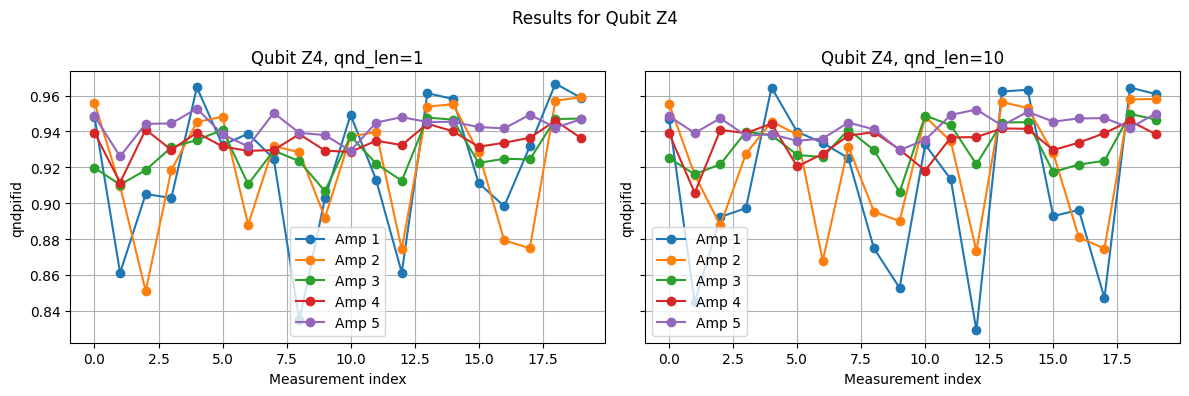

In [54]:
plot_results(result, [qubits[2]], 'qndpifid')